## 1. Środowisko i rozpakowanie danych
manul dataset umieść na gdrive Colab Notebooks


In [ ]:
import os
import glob
import shutil
import zipfile
import random
import numpy as np
import torch
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
from google.colab import drive, files

if not os.path.isdir("/content/drive/MyDrive"):
    drive.mount("/content/drive")

DATASET_DRIVE_PATH = "/content/drive/MyDrive/Colab Notebooks/manul_dataset.zip"

def find_dataset_zip():
    candidates = [
        DATASET_DRIVE_PATH,
        "/content/drive/MyDrive/manul_dataset.zip",
        "/content/drive/MyDrive/ManulDetector/manul_dataset.zip",
        "manul_dataset.zip",
        "/content/manul_dataset.zip",
    ]
    for path in candidates:
        if os.path.isfile(path):
            return path
    if os.path.isdir("/content/drive/MyDrive"):
        matches = sorted(glob.glob("/content/drive/MyDrive/**/manul_dataset*.zip", recursive=True))
        if matches:
            return matches[0]
    return None

zip_path = find_dataset_zip()
if zip_path is None:
    print("Nie znaleziono pliku na Drive. Wskaż plik manul_dataset.zip ze swojego dysku:")
    uploaded = files.upload()
    zip_candidates = [fn for fn in uploaded.keys() if fn.lower().endswith(".zip")]
    if not zip_candidates:
        raise FileNotFoundError(f"Brak archiwum pod ścieżką: {DATASET_DRIVE_PATH}")
    zip_path = zip_candidates[0]

print(f"Wczytywanie bazy ze ścieżki: {zip_path}")
if os.path.isdir("data"):
    shutil.rmtree("data")

with zipfile.ZipFile(zip_path, "r") as zf:
    zf.extractall(".")

DATA_DIR = "data/cropped" if os.path.isdir("data/cropped") else "cropped"
classes = sorted(os.listdir(DATA_DIR))
print(f"\nSukces! Liczba klas: {len(classes)} -> {classes}")
total_imgs = 0
for c in classes:
    cnt = len(os.listdir(os.path.join(DATA_DIR, c)))
    total_imgs += cnt
    print(f"  - {c:12s}: {cnt} wyciętych zdjęć")
print(f"Łącznie rozpakowano: {total_imgs} zdjęć")

Wczytywanie bazy ze ścieżki: /content/drive/MyDrive/Colab Notebooks/manul_dataset.zip

Sukces! Liczba klas: 5 -> ['abrikos', 'bol', 'grusha', 'nagomu', 'primula']
  - abrikos     : 99 wyciętych zdjęć
  - bol         : 277 wyciętych zdjęć
  - grusha      : 214 wyciętych zdjęć
  - nagomu      : 245 wyciętych zdjęć
  - primula     : 277 wyciętych zdjęć
Łącznie rozpakowano: 1112 zdjęć


## 2. Podział na zbiory (Train, Val, Test) oraz Augmentacja Danych
Stosujemy stratyfikowany podział: **70% zbiór treningowy**, **15% zbiór walidacyjny**, **15% zbiór testowy**.


In [ ]:
import random
import numpy as np
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Transformacje dla zbioru treningowego (Augmentacja zapobiegająca przeuczeniu)
train_transforms = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.85, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=12),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Transformacje dla zbioru walidacyjnego i testowego (tylko normalizacja bez augmentacji)
eval_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

base_dataset = datasets.ImageFolder(DATA_DIR)
class_names = base_dataset.classes
num_classes = len(class_names)
total_samples = len(base_dataset)

from collections import defaultdict
class_indices = defaultdict(list)
for idx, (_, label) in enumerate(base_dataset.samples):
    class_indices[label].append(idx)

train_indices, val_indices, test_indices = [], [], []

for label, indices in class_indices.items():
    random.shuffle(indices)
    n = len(indices)
    n_train = int(0.70 * n)
    n_val = int(0.15 * n)
    train_indices.extend(indices[:n_train])
    val_indices.extend(indices[n_train:n_train + n_val])
    test_indices.extend(indices[n_train + n_val:])

train_dataset = Subset(datasets.ImageFolder(DATA_DIR, transform=train_transforms), train_indices)
val_dataset = Subset(datasets.ImageFolder(DATA_DIR, transform=eval_transforms), val_indices)
test_dataset = Subset(datasets.ImageFolder(DATA_DIR, transform=eval_transforms), test_indices)

BATCH_SIZE = 16
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"Liczba próbek ogółem: {total_samples}")
print(f"  - training:  {len(train_indices)} ({len(train_indices)/total_samples:.1%})")
print(f"  - validation: {len(val_indices)} ({len(val_indices)/total_samples:.1%})")
print(f"  - test:     {len(test_indices)} ({len(test_indices)/total_samples:.1%})")


Liczba próbek ogółem: 1112
  - training:  775 (69.7%)
  - validation: 164 (14.7%)
  - test:     173 (15.6%)


### Podgląd przykładowych wykadrowanych manuli


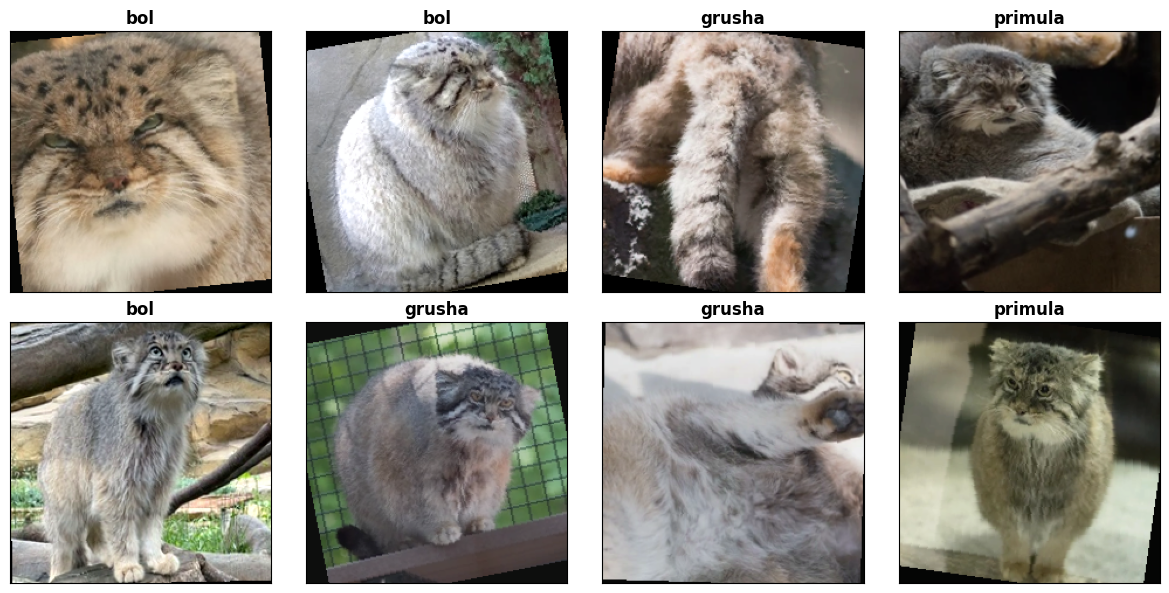

In [ ]:
def imshow_batch(images, labels, classes):
    images = images.numpy().transpose((0, 2, 3, 1))
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    images = std * images + mean
    images = np.clip(images, 0, 1)

    fig = plt.figure(figsize=(12, 6))
    for idx in range(min(8, len(images))):
        ax = fig.add_subplot(2, 4, idx + 1, xticks=[], yticks=[])
        plt.imshow(images[idx])
        ax.set_title(classes[labels[idx]], fontsize=12, fontweight="bold")
    plt.tight_layout()
    plt.show()

dataiter = iter(train_loader)
images, labels = next(dataiter)
imshow_batch(images, labels, class_names)


## 3. Modułowa Architektura Sieci Neuronowej (`CustomCNN`)
Zgodnie z wymaganiami uczelnianymi, klasa sieci pozwala na pełną parametryzację:
- Liczby bloków konwolucyjnych i filtrów (np. `[32, 64]`, `[32, 64, 128]`, `[32, 64, 128, 256]`)
- Liczby neuronów w warstwie gęstej (`fc_units`)
- Funkcji aktywacji (`ReLU`, `LeakyReLU`, `GELU`)
- Dropoutu i Batch Normalization


In [ ]:
import torch.nn as nn
import torch.nn.functional as F
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
class CustomCNN(nn.Module):
    def __init__(self, conv_channels=[32, 64, 128], fc_units=256, activation_fn=nn.ReLU, dropout_rate=0.4, num_classes=5):
        super(CustomCNN, self).__init__()

        layers = []
        in_c = 3
        for out_c in conv_channels:
            layers.append(nn.Conv2d(in_c, out_c, kernel_size=3, padding=1))
            layers.append(nn.BatchNorm2d(out_c))
            layers.append(activation_fn())
            layers.append(nn.MaxPool2d(kernel_size=2, stride=2))
            in_c = out_c

        self.features = nn.Sequential(*layers)
        self.adaptive_pool = nn.AdaptiveAvgPool2d((4, 4))

        flat_features = in_c * 4 * 4
        self.classifier = nn.Sequential(
            nn.Dropout(dropout_rate),
            nn.Linear(flat_features, fc_units),
            nn.BatchNorm1d(fc_units),
            activation_fn(),
            nn.Dropout(dropout_rate),
            nn.Linear(fc_units, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.adaptive_pool(x)
        x = torch.flatten(x, 1)
        x = self.classifier(x)
        return x

# Testowy przebieg w celu weryfikacji wymiarów tensorów
test_model = CustomCNN().to(device)
dummy_input = torch.randn(2, 3, 224, 224).to(device)
dummy_out = test_model(dummy_input)
print(f"Struktura modelu zdefiniowana poprawnie! Kształt wyjścia: {dummy_out.shape}")


Struktura modelu zdefiniowana poprawnie! Kształt wyjścia: torch.Size([2, 5])


## 4. Pętla Trenująca, Early Stopping i Kryteria Błędu (Cross-Entropy + MSE)
- Implementacja algorytmu uczenia się (SGD / Adam)
- Warunek zatrzymania: Early Stopping
- Kryterium pomiaru błędu: Cross-Entropy Loss oraz pomocniczo błąd średniokwadratowy MSE


In [ ]:
import copy
from sklearn.metrics import accuracy_score, f1_score

def train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=40, patience=8, device=device):
    best_model_wts = copy.deepcopy(model.state_dict())
    best_val_loss = float("inf")
    patience_counter = 0

    history = {
        "train_loss": [], "val_loss": [],
        "train_mse": [], "val_mse": [],
        "train_acc": [], "val_acc": []
    }

    mse_criterion = nn.MSELoss()

    for epoch in range(1, num_epochs + 1):
        # --- training ---
        model.train()
        running_loss = 0.0
        running_mse = 0.0
        all_preds = []
        all_targets = []

        for inputs, targets in train_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            optimizer.zero_grad()

            outputs = model(inputs)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)

            # MSE
            with torch.no_grad():
                probs = F.softmax(outputs, dim=1)
                one_hot_targets = F.one_hot(targets, num_classes=num_classes).float()
                mse = mse_criterion(probs, one_hot_targets)
                running_mse += mse.item() * inputs.size(0)

            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(targets.cpu().numpy())

        epoch_train_loss = running_loss / len(train_loader.dataset)
        epoch_train_mse = running_mse / len(train_loader.dataset)
        epoch_train_acc = accuracy_score(all_targets, all_preds)

        # --- FAZA WALIDACYJNA ---
        model.eval()
        running_val_loss = 0.0
        running_val_mse = 0.0
        val_preds = []
        val_targets = []

        with torch.no_grad():
            for inputs, targets in val_loader:
                inputs, targets = inputs.to(device), targets.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, targets)

                running_val_loss += loss.item() * inputs.size(0)
                probs = F.softmax(outputs, dim=1)
                one_hot_targets = F.one_hot(targets, num_classes=num_classes).float()
                running_val_mse += mse_criterion(probs, one_hot_targets).item() * inputs.size(0)

                _, preds = torch.max(outputs, 1)
                val_preds.extend(preds.cpu().numpy())
                val_targets.extend(targets.cpu().numpy())

        epoch_val_loss = running_val_loss / len(val_loader.dataset)
        epoch_val_mse = running_val_mse / len(val_loader.dataset)
        epoch_val_acc = accuracy_score(val_targets, val_preds)

        history["train_loss"].append(epoch_train_loss)
        history["val_loss"].append(epoch_val_loss)
        history["train_mse"].append(epoch_train_mse)
        history["val_mse"].append(epoch_val_mse)
        history["train_acc"].append(epoch_train_acc)
        history["val_acc"].append(epoch_val_acc)

        if epoch % 5 == 0 or epoch == 1:
            print(f"Epoka {epoch:02d}/{num_epochs:02d} | "
                  f"Train Loss: {epoch_train_loss:.4f} (Acc: {epoch_train_acc:.1%}) | "
                  f"Val Loss: {epoch_val_loss:.4f} (Acc: {epoch_val_acc:.1%})")

        # Early Stopping
        if epoch_val_loss < best_val_loss:
            best_val_loss = epoch_val_loss
            best_model_wts = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"-> Early stopping w epoce {epoch}! Najlepszy Val Loss: {best_val_loss:.4f}")
                break

    model.load_state_dict(best_model_wts)
    return model, history

def evaluate_on_test(model, test_loader, criterion, device=device):
    model.eval()
    running_loss = 0.0
    running_mse = 0.0
    all_preds = []
    all_targets = []
    mse_criterion = nn.MSELoss()

    with torch.no_grad():
        for inputs, targets in test_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            running_loss += loss.item() * inputs.size(0)

            probs = F.softmax(outputs, dim=1)
            one_hot_targets = F.one_hot(targets, num_classes=num_classes).float()
            running_mse += mse_criterion(probs, one_hot_targets).item() * inputs.size(0)

            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(targets.cpu().numpy())

    test_loss = running_loss / len(test_loader.dataset)
    test_mse = running_mse / len(test_loader.dataset)
    test_acc = accuracy_score(all_targets, all_preds)
    test_f1 = f1_score(all_targets, all_preds, average="weighted")
    return test_loss, test_mse, test_acc, test_f1, all_preds, all_targets


## 5. Seria Eksperymentów
przeprowadzamy serię eksperymentów badających wpływ:
1. **Współczynnika uczenia (*Learning Rate*):** `0.01`, `0.001`, `0.0001`
2. **Funkcji aktywacji:** `ReLU`, `LeakyReLU`, `GELU`
3. **Liczby warstw ukrytych i filtrów splotowych:**
   - Model A (2 bloki): `[32, 64]`
   - Model B (3 bloki): `[32, 64, 128]`
   - Model C (4 bloki): `[32, 64, 128, 256]`
4. **Liczby neuronów w warstwie gęstej (FC):** `128` vs `256` vs `512`


In [ ]:
experiments_results = {}
criterion = nn.CrossEntropyLoss()

# --- EKSPERYMENT 1: Wpływ Learning Rate ---
print("==================================================")
print("EKSPERYMENT 1: Wpływ Learning Rate (lr = 0.01, 0.001, 0.0001)")
print("==================================================")

lr_list = [0.01, 0.001, 0.0001]
for lr in lr_list:
    name = f"LR_{lr}"
    print(f"\n--- Trening: {name} ---")
    model = CustomCNN(conv_channels=[32, 64, 128], fc_units=256, activation_fn=nn.ReLU).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    trained_model, hist = train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=35, patience=7)
    test_loss, test_mse, test_acc, test_f1, _, _ = evaluate_on_test(trained_model, test_loader, criterion)

    experiments_results[name] = {
        "history": hist,
        "test_acc": test_acc,
        "test_f1": test_f1,
        "test_loss": test_loss,
        "test_mse": test_mse,
        "model": trained_model
    }
    print(f"Wynik testowy {name}: Acc = {test_acc:.1%}, F1 = {test_f1:.3f}, Loss = {test_loss:.4f}, MSE = {test_mse:.4f}")


EKSPERYMENT 1: Wpływ Learning Rate (lr = 0.01, 0.001, 0.0001)

--- Trening: LR_0.01 ---
Epoka 01/35 | Train Loss: 1.5007 (Acc: 43.2%) | Val Loss: 1.3013 (Acc: 49.4%)
Epoka 05/35 | Train Loss: 1.1067 (Acc: 55.9%) | Val Loss: 0.8556 (Acc: 68.3%)
Epoka 10/35 | Train Loss: 0.9549 (Acc: 65.4%) | Val Loss: 1.1497 (Acc: 59.1%)
Epoka 15/35 | Train Loss: 0.8890 (Acc: 67.4%) | Val Loss: 0.8451 (Acc: 68.3%)
Epoka 20/35 | Train Loss: 0.8275 (Acc: 69.0%) | Val Loss: 0.8805 (Acc: 66.5%)
-> Early stopping w epoce 23! Najlepszy Val Loss: 0.7963
Wynik testowy LR_0.01: Acc = 68.8%, F1 = 0.673, Loss = 0.9086, MSE = 0.0902

--- Trening: LR_0.001 ---
Epoka 01/35 | Train Loss: 1.2601 (Acc: 50.8%) | Val Loss: 0.9924 (Acc: 58.5%)
Epoka 05/35 | Train Loss: 0.9732 (Acc: 60.8%) | Val Loss: 0.9653 (Acc: 65.2%)
Epoka 10/35 | Train Loss: 0.8524 (Acc: 67.1%) | Val Loss: 0.7901 (Acc: 70.1%)
Epoka 15/35 | Train Loss: 0.7977 (Acc: 70.3%) | Val Loss: 0.8228 (Acc: 70.1%)
Epoka 20/35 | Train Loss: 0.6273 (Acc: 75.2%) | Va

In [ ]:
# --- EKSPERYMENT 2: Wpływ Funkcji Aktywacji ---
print("==================================================")
print("EKSPERYMENT 2: Funkcje Aktywacji (ReLU, LeakyReLU, GELU)")
print("==================================================")

activations = {
    "Act_ReLU": nn.ReLU,
    "Act_LeakyReLU": nn.LeakyReLU,
    "Act_GELU": nn.GELU
}

for act_name, act_fn in activations.items():
    if act_name in experiments_results:
        continue
    print(f"\n--- Trening: {act_name} ---")
    model = CustomCNN(conv_channels=[32, 64, 128], fc_units=256, activation_fn=act_fn).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

    trained_model, hist = train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=35, patience=7)
    test_loss, test_mse, test_acc, test_f1, _, _ = evaluate_on_test(trained_model, test_loader, criterion)

    experiments_results[act_name] = {
        "history": hist,
        "test_acc": test_acc,
        "test_f1": test_f1,
        "test_loss": test_loss,
        "test_mse": test_mse,
        "model": trained_model
    }
    print(f"Wynik testowy {act_name}: Acc = {test_acc:.1%}, F1 = {test_f1:.3f}")


EKSPERYMENT 2: Funkcje Aktywacji (ReLU, LeakyReLU, GELU)

--- Trening: Act_ReLU ---
Epoka 01/35 | Train Loss: 1.3182 (Acc: 47.2%) | Val Loss: 1.2694 (Acc: 48.8%)
Epoka 05/35 | Train Loss: 0.9157 (Acc: 65.2%) | Val Loss: 0.9331 (Acc: 65.2%)
Epoka 10/35 | Train Loss: 0.8105 (Acc: 69.0%) | Val Loss: 0.7805 (Acc: 68.9%)
Epoka 15/35 | Train Loss: 0.7429 (Acc: 72.3%) | Val Loss: 0.7077 (Acc: 73.8%)
Epoka 20/35 | Train Loss: 0.6615 (Acc: 73.7%) | Val Loss: 0.7297 (Acc: 75.6%)
-> Early stopping w epoce 20! Najlepszy Val Loss: 0.6759
Wynik testowy Act_ReLU: Acc = 69.4%, F1 = 0.677

--- Trening: Act_LeakyReLU ---
Epoka 01/35 | Train Loss: 1.3324 (Acc: 45.4%) | Val Loss: 1.1616 (Acc: 53.7%)
Epoka 05/35 | Train Loss: 0.9364 (Acc: 64.6%) | Val Loss: 0.8874 (Acc: 65.2%)
Epoka 10/35 | Train Loss: 0.7931 (Acc: 69.3%) | Val Loss: 0.9144 (Acc: 65.9%)
Epoka 15/35 | Train Loss: 0.7066 (Acc: 71.4%) | Val Loss: 0.7842 (Acc: 71.3%)
Epoka 20/35 | Train Loss: 0.6849 (Acc: 75.4%) | Val Loss: 0.7277 (Acc: 75.6%)

In [ ]:
# --- EKSPERYMENT 3: Głębokość sieci i filtry konwolucyjne ---
print("==================================================")
print("EKSPERYMENT 3: Liczba warstw splotowych i filtrów")
print("==================================================")

depth_configs = {
    "Conv_2_Layers_[32,64]": [32, 64],
    "Conv_3_Layers_[32,64,128]": [32, 64, 128],
    "Conv_4_Layers_[32,64,128,256]": [32, 64, 128, 256]
}

for cfg_name, channels in depth_configs.items():
    if cfg_name in experiments_results:
        continue
    print(f"\n--- Trening: {cfg_name} ---")
    model = CustomCNN(conv_channels=channels, fc_units=256, activation_fn=nn.ReLU).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

    trained_model, hist = train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=35, patience=7)
    test_loss, test_mse, test_acc, test_f1, _, _ = evaluate_on_test(trained_model, test_loader, criterion)

    experiments_results[cfg_name] = {
        "history": hist,
        "test_acc": test_acc,
        "test_f1": test_f1,
        "test_loss": test_loss,
        "test_mse": test_mse,
        "model": trained_model
    }
    print(f"Wynik testowy {cfg_name}: Acc = {test_acc:.1%}, F1 = {test_f1:.3f}")


EKSPERYMENT 3: Liczba warstw splotowych i filtrów

--- Trening: Conv_2_Layers_[32,64] ---
Epoka 01/35 | Train Loss: 1.3802 (Acc: 44.8%) | Val Loss: 1.0988 (Acc: 58.5%)
Epoka 05/35 | Train Loss: 0.9666 (Acc: 63.6%) | Val Loss: 0.8977 (Acc: 62.8%)
Epoka 10/35 | Train Loss: 0.8964 (Acc: 65.8%) | Val Loss: 0.7712 (Acc: 72.6%)
Epoka 15/35 | Train Loss: 0.8051 (Acc: 69.0%) | Val Loss: 0.7723 (Acc: 72.0%)
Epoka 20/35 | Train Loss: 0.7671 (Acc: 71.0%) | Val Loss: 0.7762 (Acc: 67.7%)
-> Early stopping w epoce 24! Najlepszy Val Loss: 0.7304
Wynik testowy Conv_2_Layers_[32,64]: Acc = 67.1%, F1 = 0.653

--- Trening: Conv_3_Layers_[32,64,128] ---
Epoka 01/35 | Train Loss: 1.3057 (Acc: 47.1%) | Val Loss: 1.1057 (Acc: 59.1%)
Epoka 05/35 | Train Loss: 0.9223 (Acc: 63.0%) | Val Loss: 0.8896 (Acc: 64.6%)
Epoka 10/35 | Train Loss: 0.8198 (Acc: 67.1%) | Val Loss: 0.7306 (Acc: 74.4%)
Epoka 15/35 | Train Loss: 0.7408 (Acc: 70.8%) | Val Loss: 0.7530 (Acc: 71.3%)
-> Early stopping w epoce 17! Najlepszy Val Lo

## 6. Zestawienie Wyników Eksperymentów (Tabela i Wykresy do Sprawozdania)


,Eksperyment / Konfiguracja,Test Accuracy,Test F1-Score,Test Cross-Entropy Loss,Test MSE Loss,Epok przed Early Stop
0,LR_0.01,68.79%,0.673,0.9086,0.0902,23
1,LR_0.001,68.79%,0.675,0.8684,0.0886,26
2,LR_0.0001,72.83%,0.714,0.8333,0.0811,35
3,Act_ReLU,69.36%,0.677,0.8651,0.0861,20
4,Act_LeakyReLU,68.21%,0.676,0.8780,0.0858,35
5,Act_GELU,71.10%,0.704,0.7965,0.0808,30
6,"Conv_2_Layers_[32,64]",67.05%,0.653,0.8601,0.0879,24
7,"Conv_3_Layers_[32,64,128]",69.94%,0.683,0.8527,0.0853,17
8,"Conv_4_Layers_[32,64,128,256]",71.10%,0.704,0.7867,0.0805,35


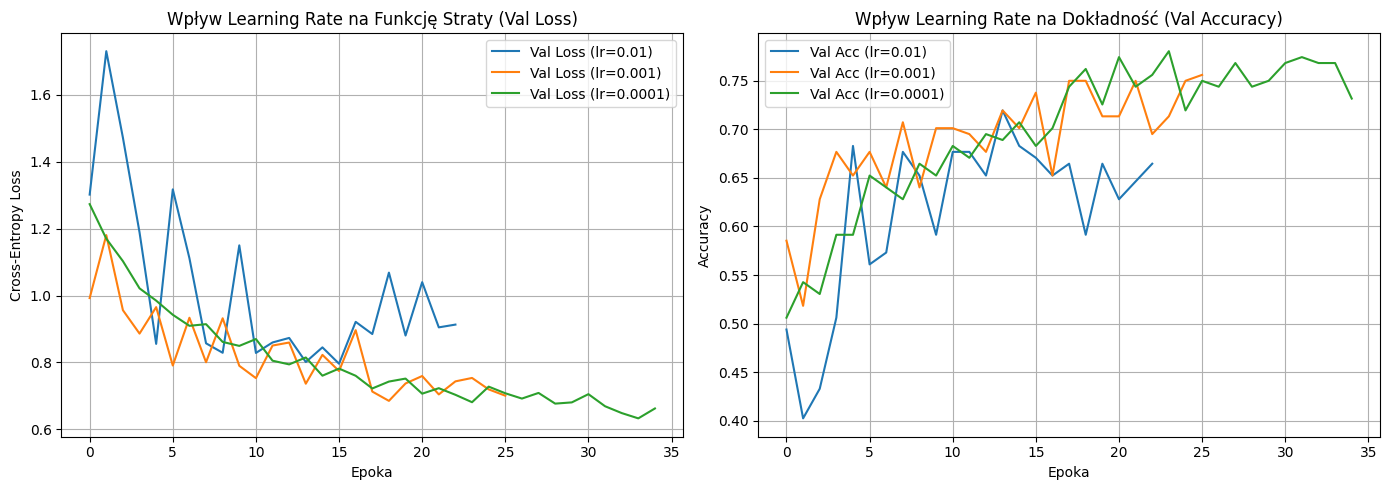

Zapisano wykres na Google Drive: /content/drive/MyDrive/Colab Notebooks/lr_comparison.png


In [ ]:
import os
import shutil
import pandas as pd
import matplotlib.pyplot as plt

summary_data = []
for name, data in experiments_results.items():
    summary_data.append({
        "Eksperyment / Konfiguracja": name,
        "Test Accuracy": f"{data['test_acc']:.2%}",
        "Test F1-Score": f"{data['test_f1']:.3f}",
        "Test Cross-Entropy Loss": f"{data['test_loss']:.4f}",
        "Test MSE Loss": f"{data['test_mse']:.4f}",
        "Epok przed Early Stop": len(data["history"]["val_loss"])
    })

df_results = pd.DataFrame(summary_data)
display(df_results)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for lr in [0.01, 0.001, 0.0001]:
    key = f"LR_{lr}"
    if key in experiments_results:
        hist = experiments_results[key]["history"]
        axes[0].plot(hist["val_loss"], label=f"Val Loss (lr={lr})")
        axes[1].plot(hist["val_acc"], label=f"Val Acc (lr={lr})")

axes[0].set_title("Wpływ Learning Rate na Funkcję Straty (Val Loss)")
axes[0].set_xlabel("Epoka")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].grid(True)
axes[0].legend()

axes[1].set_title("Wpływ Learning Rate na Dokładność (Val Accuracy)")
axes[1].set_xlabel("Epoka")
axes[1].set_ylabel("Accuracy")
axes[1].grid(True)
axes[1].legend()

plt.tight_layout()
plt.savefig("lr_comparison.png", dpi=300)
plt.show()

if os.path.isdir("/content/drive/MyDrive"):
    drive_out_dir = "/content/drive/MyDrive/Colab Notebooks"
    os.makedirs(drive_out_dir, exist_ok=True)
    shutil.copy("lr_comparison.png", os.path.join(drive_out_dir, "lr_comparison.png"))
    print(f"Zapisano wykres na Google Drive: {os.path.join(drive_out_dir, 'lr_comparison.png')}")

## 7. Macierz Pomyłek (Confusion Matrix) Najlepszego Modelu
Niezbędna do sprawozdania w celu analizy, które manule są do siebie najbardziej podobne wizualnie.


Najlepszy model: LR_0.0001 (Dokładność testowa: 72.8%)

--- Raport Klasyfikacji ---
              precision    recall  f1-score   support

     abrikos       0.25      0.12      0.17        16
         bol       0.72      0.79      0.76        43
      grusha       0.74      0.79      0.76        33
      nagomu       0.63      0.63      0.63        38
     primula       0.89      0.93      0.91        43

    accuracy                           0.73       173
   macro avg       0.65      0.65      0.65       173
weighted avg       0.70      0.73      0.71       173



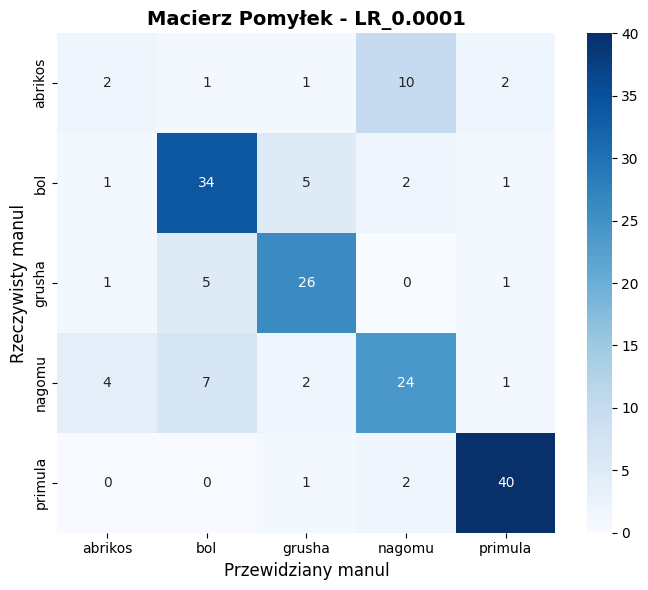

Zapisano macierz pomyłek na Google Drive: /content/drive/MyDrive/Colab Notebooks/confusion_matrix_custom_cnn.png


In [ ]:
import os
import shutil
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

# best model
best_exp_name = max(experiments_results, key=lambda k: experiments_results[k]["test_acc"])
best_exp = experiments_results[best_exp_name]
best_model = best_exp["model"]

print(f"Najlepszy model: {best_exp_name} (Dokładność testowa: {best_exp['test_acc']:.1%})")

# ewaluacja i predykcje
_, _, _, _, test_preds, test_targets = evaluate_on_test(best_model, test_loader, criterion)

print("\n--- Raport Klasyfikacji ---")
print(classification_report(test_targets, test_preds, target_names=class_names))

cm = confusion_matrix(test_targets, test_preds)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.title(f"Macierz Pomyłek - {best_exp_name}", fontsize=14, fontweight="bold")
plt.xlabel("Przewidziany manul", fontsize=12)
plt.ylabel("Rzeczywisty manul", fontsize=12)
plt.tight_layout()
plt.savefig("confusion_matrix_custom_cnn.png", dpi=300)
plt.show()

if os.path.isdir("/content/drive/MyDrive"):
    drive_out_dir = "/content/drive/MyDrive/Colab Notebooks"
    os.makedirs(drive_out_dir, exist_ok=True)
    shutil.copy("confusion_matrix_custom_cnn.png", os.path.join(drive_out_dir, "confusion_matrix_custom_cnn.png"))
    print(f"Zapisano macierz pomyłek na Google Drive: {os.path.join(drive_out_dir, 'confusion_matrix_custom_cnn.png')}")

In [ ]:
import os
import torch
from google.colab import drive, files

if not os.path.isdir("/content/drive/MyDrive"):
    drive.mount("/content/drive")

conv_channels_ckpt = [m.out_channels for m in best_model.features if isinstance(m, torch.nn.Conv2d)]
act_modules_ckpt = [m for m in best_model.features if isinstance(m, (torch.nn.ReLU, torch.nn.LeakyReLU, torch.nn.GELU))]
activation_name_ckpt = type(act_modules_ckpt[0]).__name__ if act_modules_ckpt else "ReLU"
linear_layers_ckpt = [m for m in best_model.classifier if isinstance(m, torch.nn.Linear)]
fc_units_ckpt = linear_layers_ckpt[0].out_features
dropout_layers_ckpt = [m for m in best_model.classifier if isinstance(m, torch.nn.Dropout)]
dropout_rate_ckpt = dropout_layers_ckpt[0].p if dropout_layers_ckpt else 0.4

checkpoint = {
    "model_type": "custom_cnn",
    "model_state_dict": best_model.state_dict(),
    "best_exp_name": best_exp_name,
    "class_names": class_names,
    "conv_channels": conv_channels_ckpt,
    "fc_units": fc_units_ckpt,
    "activation": activation_name_ckpt,
    "dropout_rate": dropout_rate_ckpt,
    "test_acc": float(best_exp["test_acc"]),
}

local_cnn_path = "manul_best_model.pth"
torch.save(checkpoint, local_cnn_path)
print(f"Zapisano lokalnie: {os.path.abspath(local_cnn_path)}")

drive_save_dir = "/content/drive/MyDrive/Colab Notebooks"
os.makedirs(drive_save_dir, exist_ok=True)
drive_cnn_path = os.path.join(drive_save_dir, "manul_best_model.pth")
torch.save(checkpoint, drive_cnn_path)
print(f"Zapisano model CustomCNN na Google Drive: {drive_cnn_path}")

try:
    files.download(local_cnn_path)
except Exception:
    pass

Zapisano lokalnie: /content/manul_best_model.pth
Zapisano model CustomCNN na Google Drive: /content/drive/MyDrive/Colab Notebooks/manul_best_model.pth


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8. Transfer Learning (Fine-Tuning ResNet-50)
Porównanie naszej sieci z modelem pretrenowanym


In [ ]:
from torchvision.models import resnet50, ResNet50_Weights

print("Pobieranie wag pretrenowanego modelu ResNet-50...")
weights = ResNet50_Weights.DEFAULT
resnet = resnet50(weights=weights)

in_features = resnet.fc.in_features
resnet.fc = torch.nn.Sequential(
    torch.nn.Dropout(0.4),
    torch.nn.Linear(in_features, num_classes)
)
resnet = resnet.to(device)

optimizer_resnet = torch.optim.Adam(resnet.parameters(), lr=0.0001)

print("\nRozpoczynam Fine-Tuning ResNet-50...")
resnet_trained, resnet_hist = train_model(
    resnet, train_loader, val_loader, criterion, optimizer_resnet, num_epochs=20, patience=5
)

r_loss, r_mse, r_acc, r_f1, r_preds, r_targets = evaluate_on_test(resnet_trained, test_loader, criterion)

print(f"\n==========================================")
print(f"WYNIKI TRANSFER LEARNING (ResNet-50):")
print(f"  - Test Accuracy: {r_acc:.1%}")
print(f"  - Test F1-Score: {r_f1:.3f}")
print(f"  - Test Cross-Entropy: {r_loss:.4f}")
print(f"  - Test MSE: {r_mse:.4f}")
print(f"==========================================")

# porównanie
print(f"\nPORÓWNANIE DO SPRAWOZDANIA:")
print(f"  Custom CNN ({best_exp_name}): {best_exp['test_acc']:.1%}")
print(f"  ResNet-50 Fine-Tuning:         {r_acc:.1%}")

Pobieranie wag pretrenowanego modelu ResNet-50...

Rozpoczynam Fine-Tuning ResNet-50...
Epoka 01/20 | Train Loss: 1.3513 (Acc: 48.3%) | Val Loss: 0.8540 (Acc: 71.3%)
Epoka 05/20 | Train Loss: 0.1782 (Acc: 94.6%) | Val Loss: 0.1654 (Acc: 95.1%)
Epoka 10/20 | Train Loss: 0.0684 (Acc: 97.5%) | Val Loss: 0.1966 (Acc: 94.5%)
-> Early stopping w epoce 10! Najlepszy Val Loss: 0.1654

WYNIKI TRANSFER LEARNING (ResNet-50):
  - Test Accuracy: 91.9%
  - Test F1-Score: 0.919
  - Test Cross-Entropy: 0.2723
  - Test MSE: 0.0248

PORÓWNANIE DO SPRAWOZDANIA:
  Custom CNN (LR_0.0001): 72.8%
  ResNet-50 Fine-Tuning:         91.9%


In [ ]:
import os
import torch
from google.colab import drive, files

if not os.path.isdir("/content/drive/MyDrive"):
    drive.mount("/content/drive")

resnet_checkpoint = {
    "model_type": "resnet50",
    "model_state_dict": resnet_trained.state_dict(),
    "class_names": class_names,
    "num_classes": num_classes,
    "dropout_rate": 0.4,
    "test_acc": float(r_acc),
}

local_resnet_path = "manul_resnet50.pth"
torch.save(resnet_checkpoint, local_resnet_path)
print(f"Zapisano lokalnie: {os.path.abspath(local_resnet_path)}")

drive_save_dir = "/content/drive/MyDrive/Colab Notebooks"
os.makedirs(drive_save_dir, exist_ok=True)
drive_resnet_path = os.path.join(drive_save_dir, "manul_resnet50.pth")
torch.save(resnet_checkpoint, drive_resnet_path)
print(f"Zapisano model ResNet-50 na Google Drive: {drive_resnet_path}")

try:
    files.download(local_resnet_path)
except Exception:
    pass

Zapisano lokalnie: /content/manul_resnet50.pth
Zapisano model ResNet-50 na Google Drive: /content/drive/MyDrive/Colab Notebooks/manul_resnet50.pth


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Wykryto zapisany model: /content/drive/MyDrive/Colab Notebooks/manul_best_model.pth
Wczytano model: CustomCNN (LR_0.0001) (bez ponownego trenowania).
Wybierz zdjęcie manula z dysku komputera:


Saving HClJ6cQWMAACOTV.jpg to HClJ6cQWMAACOTV.jpg

Analizuję zdjęcie: HClJ6cQWMAACOTV.jpg
Pomyślnie zlokalizowano manula przy użyciu YOLOv8!


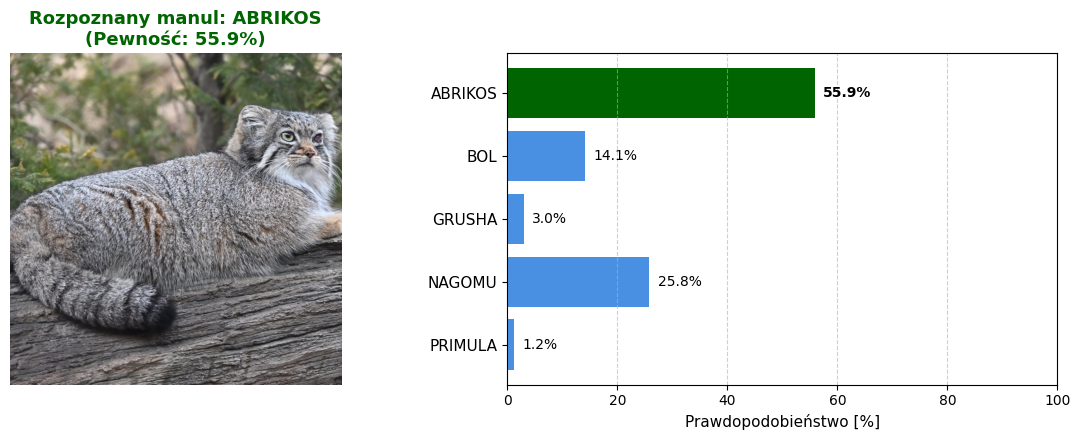

In [ ]:
!pip install -q ultralytics
import os
import glob
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from torchvision import transforms
from torchvision.models import resnet50
from ultralytics import YOLO
from google.colab import drive, files

if not os.path.isdir("/content/drive/MyDrive"):
    drive.mount("/content/drive")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DEFAULT_CLASS_NAMES = ["bol", "grusha", "nagomu", "primula", "prinsessa"]

if "eval_transforms" not in globals():
    eval_transforms = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])

if "CustomCNN" not in globals():
    class CustomCNN(nn.Module):
        def __init__(self, conv_channels=[32, 64, 128], fc_units=256, activation_fn=nn.ReLU, dropout_rate=0.4, num_classes=5):
            super(CustomCNN, self).__init__()
            layers = []
            in_c = 3
            for out_c in conv_channels:
                layers.append(nn.Conv2d(in_c, out_c, kernel_size=3, padding=1))
                layers.append(nn.BatchNorm2d(out_c))
                layers.append(activation_fn())
                layers.append(nn.MaxPool2d(kernel_size=2, stride=2))
                in_c = out_c
            self.features = nn.Sequential(*layers)
            self.adaptive_pool = nn.AdaptiveAvgPool2d((4, 4))
            flat_features = in_c * 4 * 4
            self.classifier = nn.Sequential(
                nn.Dropout(dropout_rate),
                nn.Linear(flat_features, fc_units),
                nn.BatchNorm1d(fc_units),
                activation_fn(),
                nn.Dropout(dropout_rate),
                nn.Linear(fc_units, num_classes)
            )

        def forward(self, x):
            x = self.features(x)
            x = self.adaptive_pool(x)
            x = torch.flatten(x, 1)
            x = self.classifier(x)
            return x

def find_saved_model_in_drive_or_colab():
    candidates = [
        "/content/drive/MyDrive/Colab Notebooks/manul_best_model.pth",
        "/content/drive/MyDrive/Colab Notebooks/manul_resnet50.pth",
        "/content/drive/MyDrive/ManulDetector/manul_best_model.pth",
        "/content/drive/MyDrive/ManulDetector/manul_resnet50.pth",
        "/content/drive/MyDrive/manul_best_model.pth",
        "/content/drive/MyDrive/manul_resnet50.pth",
        "manul_best_model.pth",
        "/content/manul_best_model.pth",
        "manul_resnet50.pth",
        "/content/manul_resnet50.pth",
    ]
    for path in candidates:
        if os.path.isfile(path):
            return path
    if os.path.isdir("/content/drive/MyDrive"):
        matches = sorted(glob.glob("/content/drive/MyDrive/**/*.pth", recursive=True))
        if matches:
            return matches[0]
    for d in [".", "/content"]:
        if os.path.isdir(d):
            matches = sorted(glob.glob(os.path.join(d, "*.pth")))
            if matches:
                return matches[0]
    return None

def export_memory_model_to_drive(model, filename, classes_list):
    if hasattr(model, "features") and hasattr(model, "classifier"):
        conv_channels = [m.out_channels for m in model.features if isinstance(m, nn.Conv2d)]
        act_modules = [m for m in model.features if isinstance(m, (nn.ReLU, nn.LeakyReLU, nn.GELU))]
        act_name = type(act_modules[0]).__name__ if act_modules else "ReLU"
        linear_layers = [m for m in model.classifier if isinstance(m, nn.Linear)]
        fc_units = linear_layers[0].out_features
        dropout_layers = [m for m in model.classifier if isinstance(m, nn.Dropout)]
        dropout_rate = dropout_layers[0].p if dropout_layers else 0.4
        ckpt = {
            "model_type": "custom_cnn",
            "model_state_dict": model.state_dict(),
            "class_names": classes_list,
            "conv_channels": conv_channels,
            "fc_units": fc_units,
            "activation": act_name,
            "dropout_rate": dropout_rate,
        }
    else:
        ckpt = {
            "model_type": "resnet50",
            "model_state_dict": model.state_dict(),
            "class_names": classes_list,
            "num_classes": len(classes_list),
            "dropout_rate": 0.4,
        }
    torch.save(ckpt, filename)
    if os.path.isdir("/content/drive/MyDrive"):
        drive_dir = "/content/drive/MyDrive/Colab Notebooks"
        os.makedirs(drive_dir, exist_ok=True)
        drive_path = os.path.join(drive_dir, filename)
        torch.save(ckpt, drive_path)
        return drive_path
    return filename

def load_saved_model(ckpt_path):
    try:
        ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
    except TypeError:
        ckpt = torch.load(ckpt_path, map_location=device)

    if isinstance(ckpt, nn.Module):
        loaded = ckpt.to(device)
        loaded.eval()
        cls_list = globals().get("class_names", DEFAULT_CLASS_NAMES)
        return loaded, cls_list, "Pełny obiekt modelu"

    if isinstance(ckpt, dict) and "model_state_dict" in ckpt:
        state_dict = ckpt["model_state_dict"]
        cls_list = ckpt.get("class_names", globals().get("class_names", DEFAULT_CLASS_NAMES))
        model_type = ckpt.get("model_type")
        if model_type is None:
            model_type = "resnet50" if ("fc.1.weight" in state_dict and "features.0.weight" not in state_dict) else "custom_cnn"
    else:
        state_dict = ckpt
        cls_list = globals().get("class_names", DEFAULT_CLASS_NAMES)
        model_type = "resnet50" if ("fc.1.weight" in state_dict and "features.0.weight" not in state_dict) else "custom_cnn"

    if model_type == "resnet50":
        dropout_rate = ckpt.get("dropout_rate", 0.4) if isinstance(ckpt, dict) else 0.4
        model = resnet50(weights=None)
        in_features = model.fc.in_features
        model.fc = nn.Sequential(
            nn.Dropout(dropout_rate),
            nn.Linear(in_features, len(cls_list))
        )
        info = "ResNet-50"
    else:
        act_map = {"ReLU": nn.ReLU, "LeakyReLU": nn.LeakyReLU, "GELU": nn.GELU}
        if isinstance(ckpt, dict) and "conv_channels" in ckpt:
            conv_channels = ckpt["conv_channels"]
            fc_units = ckpt.get("fc_units", 256)
            act_name = ckpt.get("activation", "ReLU")
            dropout_rate = ckpt.get("dropout_rate", 0.4)
        else:
            conv_weights = sorted(
                [(int(k.split(".")[1]), v.shape[0]) for k, v in state_dict.items() if k.startswith("features.") and k.endswith(".weight") and v.ndim == 4],
                key=lambda x: x[0]
            )
            conv_channels = [ch for _, ch in conv_weights] or [32, 64, 128]
            fc_units = state_dict["classifier.1.weight"].shape[0] if "classifier.1.weight" in state_dict else 256
            act_name = "GELU"
            dropout_rate = 0.4
        model = CustomCNN(
            conv_channels=conv_channels,
            fc_units=fc_units,
            activation_fn=act_map.get(act_name, nn.ReLU),
            dropout_rate=dropout_rate,
            num_classes=len(cls_list),
        )
        exp_label = ckpt.get("best_exp_name", act_name) if isinstance(ckpt, dict) else act_name
        info = f"CustomCNN ({exp_label})"

    model.load_state_dict(state_dict)
    model = model.to(device)
    model.eval()
    return model, cls_list, info

saved_model_path = find_saved_model_in_drive_or_colab()

if saved_model_path is not None:
    print(f"Wykryto zapisany model: {saved_model_path}")
    active_model, active_class_names, model_info = load_saved_model(saved_model_path)
    print(f"Wczytano model: {model_info} (bez ponownego trenowania).")
elif "best_model" in globals() or "resnet_trained" in globals():
    if "best_model" in globals():
        active_model = best_model
        auto_name = "manul_best_model.pth"
    else:
        active_model = resnet_trained
        auto_name = "manul_resnet50.pth"
    active_class_names = globals().get("class_names", DEFAULT_CLASS_NAMES)
    saved_to = export_memory_model_to_drive(active_model, auto_name, active_class_names)
    print(f"Wykryto model w pamięci sesji i zapisano go na Google Drive: {saved_to}")
else:
    print("Nie znaleziono zapisanego pliku .pth na Google Drive ani w pamięci. Wgraj plik .pth z komputera:")
    uploaded_ckpt = files.upload()
    pth_files = [fn for fn in uploaded_ckpt.keys() if fn.lower().endswith((".pth", ".pt"))]
    if not pth_files:
        raise RuntimeError("Nie wgrano pliku .pth i nie znaleziono zapisanego modelu na Google Drive.")
    saved_model_path = pth_files[0]
    active_model, active_class_names, model_info = load_saved_model(saved_model_path)
    print(f"Wczytano wgrany model: {model_info}.")

if "yolo_crop_model" not in globals():
    yolo_crop_model = YOLO("yolov8n.pt")

def predict_manul(image_path, model=None, use_yolo_crop=True):
    model_to_use = active_model if model is None else model
    cls_names = active_class_names if "active_class_names" in globals() else DEFAULT_CLASS_NAMES

    img = Image.open(image_path).convert("RGB")
    cropped_for_display = img
    if use_yolo_crop:
        results = yolo_crop_model(image_path, classes=[15, 16, 21], conf=0.35, verbose=False)
        boxes = results[0].boxes
        if len(boxes) > 0:
            best_idx = torch.argmax(boxes.conf).item()
            x1, y1, x2, y2 = boxes.xyxy[best_idx].tolist()
            img_w, img_h = img.size

            box_w, box_h = x2 - x1, y2 - y1
            cx, cy = (x1 + x2) / 2.0, (y1 + y2) / 2.0
            square_size = min(max(box_w, box_h) * 1.16, min(img_w, img_h))
            half = square_size / 2.0
            c_x1 = max(0, min(img_w - square_size, cx - half))
            c_y1 = max(0, min(img_h - square_size, cy - half))

            img = img.crop((c_x1, c_y1, c_x1 + square_size, c_y1 + square_size))
            cropped_for_display = img
            print("Pomyślnie zlokalizowano manula przy użyciu YOLOv8!")
        else:
            print("YOLO nie wykryło jednoznacznie sylwetki – użyto całego zdjęcia.")

    input_tensor = eval_transforms(img).unsqueeze(0).to(device)

    model_to_use.eval()
    with torch.no_grad():
        outputs = model_to_use(input_tensor)
        probs = F.softmax(outputs, dim=1).cpu().numpy()[0]

    top_class_idx = np.argmax(probs)
    top_class_name = cls_names[top_class_idx]
    top_prob = probs[top_class_idx]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

    ax1.imshow(cropped_for_display)
    ax1.set_title(f"Rozpoznany manul: {top_class_name.upper()}\n(Pewność: {top_prob:.1%})",
                  fontsize=13, fontweight="bold", color="darkgreen" if top_prob > 0.5 else "darkorange")
    ax1.axis("off")

    colors = ["darkgreen" if i == top_class_idx else "#4a90e2" for i in range(len(cls_names))]
    y_pos = np.arange(len(cls_names))
    ax2.barh(y_pos, probs * 100, color=colors)
    ax2.set_yticks(y_pos)
    ax2.set_yticklabels([c.upper() for c in cls_names], fontsize=11)
    ax2.invert_yaxis()
    ax2.set_xlabel("Prawdopodobieństwo [%]", fontsize=11)
    ax2.set_xlim(0, 100)
    ax2.grid(axis="x", linestyle="--", alpha=0.6)

    for i, v in enumerate(probs * 100):
        ax2.text(v + 1.5, i, f"{v:.1f}%", va="center", fontweight="bold" if i == top_class_idx else "normal")

    plt.tight_layout()
    plt.show()

print("Wybierz zdjęcie manula z dysku komputera:")
uploaded = files.upload()
for fn in uploaded.keys():
    print(f"\nAnalizuję zdjęcie: {fn}")
    predict_manul(fn)